   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Correlation:
              MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc      1.000000 -0.119034  0.326895  -0.062040    0.004834  0.018766   
HouseAge   -0.119034  1.000000 -0.153277  -0.077747   -0.296244  0.013191   
AveRooms    0.326895 -0.153277  1.000000   0.847621   -0.072213 -0.004852   
AveBedrms  -0.062040 -0.077747  0.847621   1.000000   -0.066197 -0.006181   
Population  0.004834 -0.296244 -0.072213  -0.066197   

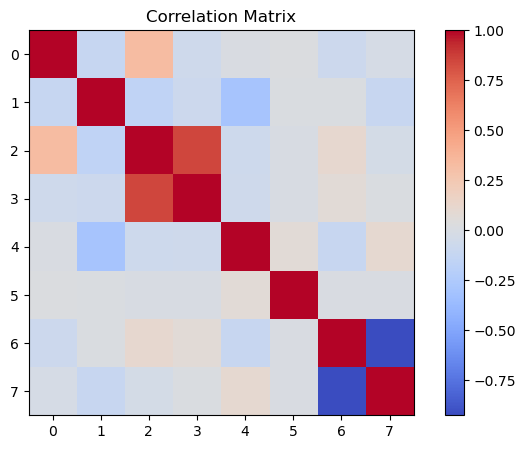


Linear Regression
MSE: 0.5558915986952444
R2: 0.5757877060324508

Ridge Regression
MSE: 0.5558548589435987
R2: 0.575815742891367

Lasso Regression
MSE: 0.5482548967938964
R2: 0.5816154300698727

Coefficients
      Feature    Linear     Ridge     Lasso
0      MedInc  0.854383  0.854327  0.800957
1    HouseAge  0.122546  0.122624  0.127087
2    AveRooms -0.294410 -0.294210 -0.162759
3   AveBedrms  0.339259  0.339008  0.206207
4  Population -0.002308 -0.002282 -0.000000
5    AveOccup -0.040829 -0.040833 -0.030602
6    Latitude -0.896929 -0.896168 -0.790113
7   Longitude -0.869842 -0.869071 -0.755674


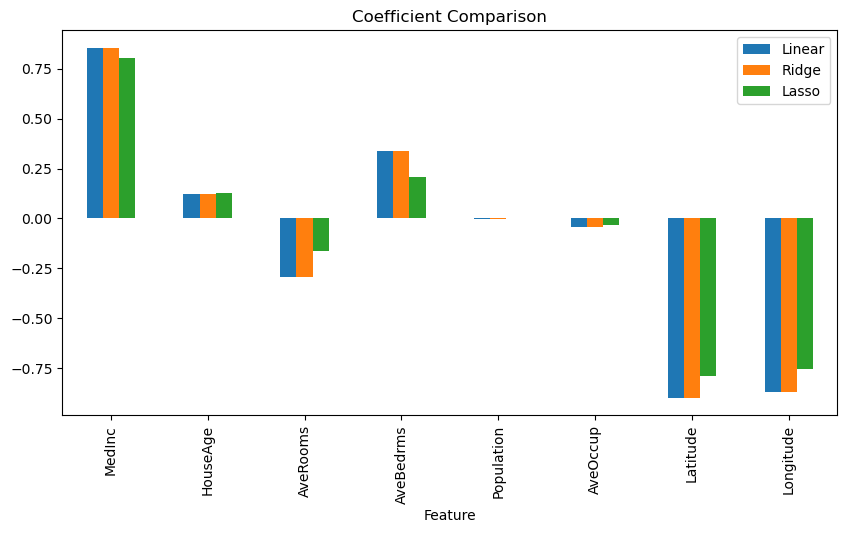

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

data = fetch_california_housing()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(X.head())

print("\nCorrelation:")
print(X.corr())

plt.figure(figsize=(8, 5))
plt.imshow(X.corr(), cmap="coolwarm")
plt.colorbar()
plt.title("Correlation Matrix")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear = LinearRegression()
ridge = Ridge(alpha=1)
lasso = Lasso(alpha=0.01)

linear.fit(X_train, y_train)
ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

linear_pred = linear.predict(X_test)
ridge_pred = ridge.predict(X_test)
lasso_pred = lasso.predict(X_test)

print("\nLinear Regression")
print("MSE:", mean_squared_error(y_test, linear_pred))
print("R2:", r2_score(y_test, linear_pred))

print("\nRidge Regression")
print("MSE:", mean_squared_error(y_test, ridge_pred))
print("R2:", r2_score(y_test, ridge_pred))

print("\nLasso Regression")
print("MSE:", mean_squared_error(y_test, lasso_pred))
print("R2:", r2_score(y_test, lasso_pred))

print("\nCoefficients")

result = pd.DataFrame({
    "Feature": data.feature_names,
    "Linear": linear.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_
})

print(result)

result.set_index("Feature").plot(kind="bar", figsize=(10, 5))
plt.title("Coefficient Comparison")
plt.show()